--- Exploratory Data Analysis (EDA) ---
First 5 rows of the dataset:
    Feature1   Feature2       Label
0  54.967142  21.788937  Category A
1  48.617357  22.803923  Category A
2  56.476885  25.415256  Category A
3  65.230299  25.269010  Category C
4  47.658466  13.111653  Category C

Dataset Summary Statistics:
          Feature1    Feature2       Label
count   200.000000  200.000000         200
unique         NaN         NaN           3
top            NaN         NaN  Category A
freq           NaN         NaN         110
mean     49.592290   20.429341         NaN
std       9.310039    4.935019         NaN
min      23.802549    3.793663         NaN
25%      42.948723   16.970812         NaN
50%      49.958081   20.394197         NaN
75%      55.008525   23.436156         NaN
max      77.201692   39.263657         NaN


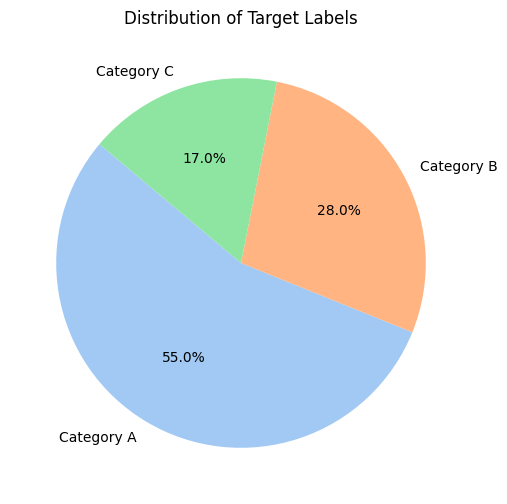


Data split successful:
Training set shape: (150, 2)
Testing set shape: (50, 2)

--- Model Evaluation ---
Model Accuracy: 52.00%

Classification Report:
              precision    recall  f1-score   support

  Category A       0.61      0.79      0.69        28
  Category B       0.27      0.21      0.24        14
  Category C       0.33      0.12      0.18         8

    accuracy                           0.52        50
   macro avg       0.41      0.38      0.37        50
weighted avg       0.47      0.52      0.48        50

--- Predictions vs Actual Labels (Sample) ---
  Actual Label Predicted Label
0   Category A      Category A
1   Category C      Category A
2   Category B      Category A
3   Category B      Category A
4   Category A      Category A
5   Category A      Category A
6   Category A      Category A
7   Category A      Category A
8   Category A      Category A
9   Category B      Category A


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Create a synthetic dataset for demonstration
np.random.seed(42)
num_samples = 200
data = {
    'Feature1': np.random.randn(num_samples) * 10 + 50,
    'Feature2': np.random.randn(num_samples) * 5 + 20,
    'Label': np.random.choice(['Category A', 'Category B', 'Category C'], size=num_samples, p=[0.5, 0.3, 0.2])
}
df = pd.DataFrame(data)

# 2. Exploratory Data Analysis (EDA)
print("--- Exploratory Data Analysis (EDA) ---")
print("First 5 rows of the dataset:")
print(df.head())
print("\nDataset Summary Statistics:")
print(df.describe(include='all'))

# 3. Draw a Pie Chart of the Label distribution
plt.figure(figsize=(6, 6))
label_counts = df['Label'].value_counts()
plt.pie(label_counts, labels=label_counts.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
plt.title('Distribution of Target Labels')
plt.show()

# 4. Split the Data into Train and Test sets
X = df[['Feature1', 'Feature2']]
y = df['Label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print(f"\nData split successful:")
print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}\n")

# 5. Train a Model & Find Accuracy
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print("--- Model Evaluation ---")
print(f"Model Accuracy: {accuracy * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# 6. Predict Actual Data and Compare with Original Labels
comparison_df = pd.DataFrame({
    'Actual Label': y_test.values,
    'Predicted Label': y_pred
})
print("--- Predictions vs Actual Labels (Sample) ---")
print(comparison_df.head(10))

In [2]:
import pickle

# Save the trained model to a file
model_filename = 'model.pkl'
with open(model_filename, 'wb') as file:
    pickle.dump(model, file)

print(f"Model successfully saved to {model_filename}")

Model successfully saved to model.pkl
